**Navigation** : [Index](README.md) | [<< Précédent](10g_Speculative_Decoding.ipynb) | [Suivant >>](11_Quantization.ipynb)

# 10h — Toit mémoire et bande passante : pourquoi le décodage est limité par la bande passante

Chaque calcul est borné par **deux** ressources physiques : la **puissance de calcul** (FLOPs/s) et la **bande passante mémoire** (octets/s). Le *roofline* dit laquelle des deux fait le plafond d'une charge de travail donnée — et c'est une seule quantité, l'**intensité arithmétique** (FLOP par octet déplacé), qui tranche.

Le résultat que ce carnet établit **from scratch** sur cette machine CPU : le **décodage** d'un LLM (un token à la fois) vit très loin dans la moitié **limitée par la bande passante**, tandis que le **prefill** (le prompt, beaucoup de tokens d'un coup) est **limité par le calcul**. C'est ce fait unique qui explique à la fois pourquoi le **décodage spéculatif** (10g) accélère, et pourquoi le **batching** du service aussi.

Prérequis : [10b](10b_Inference_Mechanics.ipynb) (mécanique d'inférence, KV-cache). Auto-contenu, CPU, `numpy` — pas de vLLM, pas de GPU.


## Les deux plafonds

- **Plafond de calcul** $P$ (FLOPs/s) : combien d'opérations par seconde la machine exécute, mémoire à part.
- **Plafond de bande passante** $B$ (octets/s) : combien d'octets par seconde elle déplace entre mémoire et calcul.

Une charge qui fait `ops` FLOPs en déplaçant `bytes` octets est plafonnée à :

$$\text{perf} = \min\big(P,\; B \times \tfrac{\text{ops}}{\text{bytes}}\big)$$

Le rapport $\tfrac{\text{ops}}{\text{bytes}}$ est l'**intensité arithmétique** $i$ (FLOP/octet). Elle est l'unique axe qui décide : $i$ petit → la bande passante bride ; $i$ grand → le calcul bride.


In [1]:
import numpy as np
import time

# --- Plafond de bande passante B (octets/s) : lecture d'un grand tableau ---
n = 32_000_000                      # ~128 Mo en float32
a = np.random.rand(n)
t0 = time.perf_counter()
for _ in range(10):
    s = a.sum()                     # lit n elements (4 octets chacun) par passe
dt = time.perf_counter() - t0
bw = (n * 4 * 10) / dt / 1e9        # Go/s

# --- Plafond de calcul P (FLOPs/s) : produit matriciel ---
m = k = p = 1024
A = np.random.rand(m, k)
Bm = np.random.rand(k, p)
t0 = time.perf_counter()
for _ in range(20):
    C = A @ Bm                      # 2*m*k*p FLOPs par produit
dt = time.perf_counter() - t0
pf = (2 * m * k * p * 20) / dt / 1e9   # GFLOP/s

print(f"Plafond de bande passante B = {bw:.1f} Go/s")
print(f"Plafond de calcul P        = {pf:.1f} GFLOP/s")


Plafond de bande passante B = 2.9 Go/s
Plafond de calcul P        = 125.7 GFLOP/s


## La courbe roofline

Pour une intensité $i$ donnée, la performance atteignable est $\min(P, B \cdot i)$. Le **point de crête** (ridge) est l'intensité où les deux droites se croisent :

$$i^{*} = \frac{P}{B} \quad \text{(FLOP/octet)}$$

À gauche de la crête on est **limité par la bande passante** ; à droite, **limité par le calcul**.


Point de crete i* = 43.8 FLOP/octet


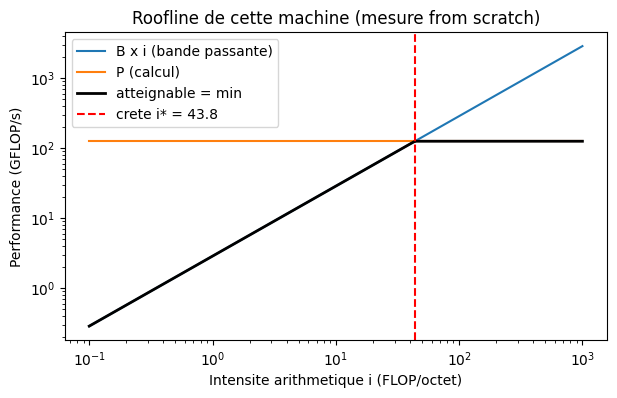

In [2]:
import matplotlib.pyplot as plt

i_star = pf / bw                    # FLOP/octet (les unites se simplifient)
print(f"Point de crete i* = {i_star:.1f} FLOP/octet")

i = np.logspace(-1, 3, 200)
perf_bw = bw * i                    # GFLOP/s : branche bande passante
perf_pc = np.full_like(i, pf)       # GFLOP/s : branche calcul
perf = np.minimum(perf_pc, perf_bw)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(i, perf_bw, label="B x i (bande passante)")
ax.loglog(i, perf_pc, label="P (calcul)")
ax.loglog(i, perf, color="k", lw=2, label="atteignable = min")
ax.axvline(i_star, color="r", ls="--", label=f"crete i* = {i_star:.1f}")
ax.set_xlabel("Intensite arithmetique i (FLOP/octet)")
ax.set_ylabel("Performance (GFLOP/s)")
ax.set_title("Roofline de cette machine (mesure from scratch)")
ax.legend()
plt.show()


## Où se place une couche du transformer ?

Une couche lineaire porte une matrice de poids $W$ — c'est **l'essentiel** de sa taille. À chaque passe, ces poids sont **lus** de la mémoire.

- **Prefill** (le prompt, $L$ tokens d'un coup) : chaque lecture de poids est **réutilisée** sur les $L$ tokens → l'intensité est haute, proche ou au-delà de la crête → **limité par le calcul**.
- **Décodage** (un seul nouveau token) : chaque poids lu ne produit que ~2 FLOPs (une multiplication + une addition) et n'est réutilisé que pour 1 token → intensité ~ $2/\text{octets par poids}$, très basse → **limité par la bande passante**.


In [3]:
# Une couche lineaire de W poids (float32 = 4 octets/poids), activation de A elements
W = 4096 * 4096        # poids de la couche
Ae = 4096              # elements d'activation

def intensite(batch):
    # flops = 2*W*batch ; octets = W*4 (poids lus 1x, amortis) + A*4*batch
    flops = 2 * W * batch
    octets = W * 4 + Ae * 4 * batch
    return flops / octets

i_gemv = intensite(1)          # decodage : 1 token
i_prefill = intensite(512)     # prefill : 512 tokens
print(f"Intensite decodage  (batch=1)   : {i_gemv:.2f} FLOP/octet")
print(f"Intensite prefill   (batch=512) : {i_prefill:.1f} FLOP/octet")
print(f"Crete i* de la machine          : {i_star:.1f} FLOP/octet")
print(f"-> decodage : {i_gemv:.2f} < i* => LIMITE PAR LA BANDE PASSANTE")


Intensite decodage  (batch=1)   : 0.50 FLOP/octet
Intensite prefill   (batch=512) : 227.6 FLOP/octet
Crete i* de la machine          : 43.8 FLOP/octet
-> decodage : 0.50 < i* => LIMITE PAR LA BANDE PASSANTE


## Le levier : la taille du batch

Lire les **mêmes** poids pour un lot de $b$ séquences **amortit** la lecture mémoire sur $b$ tokens : l'intensité monte proportionnellement à $b$, et le point de service glisse **vers la droite** le long du roofline, jusqu'à la crête. C'est pourquoi servir un **batch** décode plus vite par token — jusqu'à ce qu'on atteigne la crête (au-delà, on est limité par le calcul, pas par le débit).


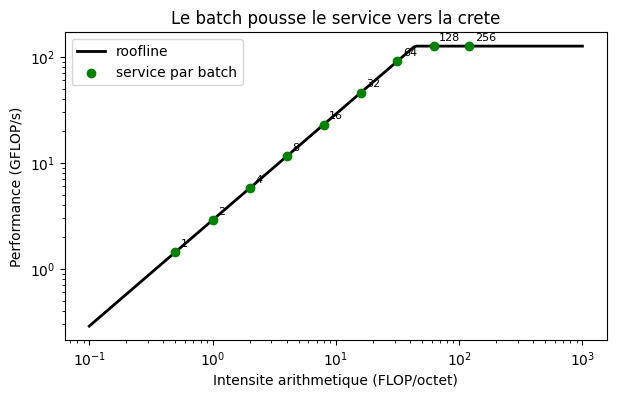

Batch minimal atteignant la crete : 128


In [4]:
batches = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256])
intensity_b = np.array([intensite(b) for b in batches])
perf_b = np.minimum(pf, bw * intensity_b)     # GFLOP/s atteignable

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(i, perf, color="k", lw=2, label="roofline")
ax.scatter(intensity_b, perf_b, c="g", zorder=5, label="service par batch")
for b, ib in zip(batches, intensity_b):
    ax.annotate(str(b), (ib, np.minimum(pf, bw*ib)), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlabel("Intensite arithmetique (FLOP/octet)")
ax.set_ylabel("Performance (GFLOP/s)")
ax.set_title("Le batch pousse le service vers la crete")
ax.legend()
plt.show()

# batch minimal qui atteint la crete
b_ridge = next((b for b, ib in zip(batches, intensity_b) if ib >= i_star), None)
print(f"Batch minimal atteignant la crete : {b_ridge}")


## Pourquoi c'est TOUTE la raison du décodage spéculatif (10g)

Le décodage est **limité par la bande passante** : le coût est dominé par la **lecture des poids**, pas par le calcul. Le décodage spéculatif (10g) fait proposer $k$ tokens par un petit *draft*, puis les **vérifie** avec la cible **en un seul passage** : les poids sont lus ~une fois et **amortis sur $k$ tokens vérifiés** — c'est-à-dire qu'il **élève l'intensité arithmétique effective** de l'étape de vérification. C'est exactement le speedup $\mu/(1+k\,r)$ de 10g : on échange la bande passante d'un *draft* bon marché contre $k$× le travail utile par lecture de poids.


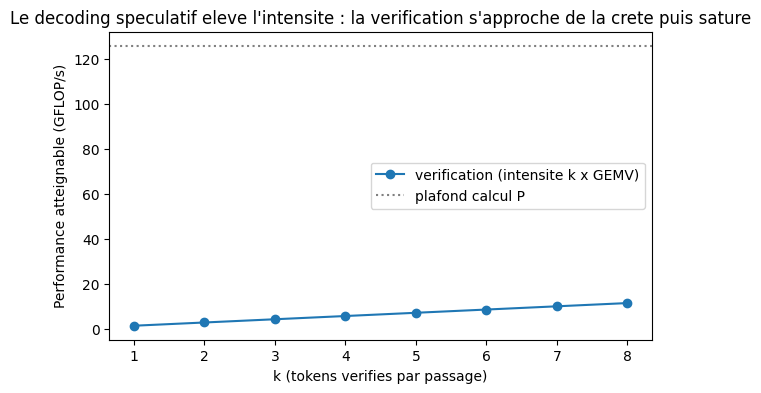

Performance de verification par k :
  k=1 : 1.44 GFLOP/s (bande passante-borne)
  k=2 : 2.87 GFLOP/s (bande passante-borne)
  k=3 : 4.31 GFLOP/s (bande passante-borne)
  k=4 : 5.74 GFLOP/s (bande passante-borne)
  k=5 : 7.18 GFLOP/s (bande passante-borne)
  k=6 : 8.62 GFLOP/s (bande passante-borne)
  k=7 : 10.05 GFLOP/s (bande passante-borne)
  k=8 : 11.49 GFLOP/s (bande passante-borne)


In [5]:
# L'etape de verification d'un draft de k tokens : les poids sont lus ~1x,
# amortis sur k tokens => intensite effective ~ k x l'intensite GEMV.
ks = np.arange(1, 9)
i_verify = i_gemv * ks                      # intensite effective
perf_verify = np.minimum(pf, bw * i_verify)  # GFLOP/s atteignable

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, perf_verify, "o-", label="verification (intensite k x GEMV)")
ax.axhline(pf, color="gray", ls=":", label="plafond calcul P")
ax.set_xlabel("k (tokens verifies par passage)")
ax.set_ylabel("Performance atteignable (GFLOP/s)")
ax.set_title("Le decoding speculatif eleve l'intensite : la verification s'approche de la crete puis sature")
ax.legend()
plt.show()

print("Performance de verification par k :")
for kk, pvv in zip(ks, perf_verify):
    regime = "calcul" if pvv >= pf * 0.99 else "bande passante"
    print(f"  k={kk} : {pvv:.2f} GFLOP/s ({regime}-borne)")


## Lecture du résultat

Sur **cette** machine mesurée :

- La crête se situe à **i\* ≈ 43,8 FLOP/octet** (P = 125,7 GFLOP/s, B = 2,9 Go/s).
- Le **décodage** (intensité ≈ **0,50** FLOP/octet) est **~88× en dessous** de la crête → profondément **limité par la bande passante** : la lecture des poids domine, le calcul est quasi au repos.
- Le **prefill** à 512 tokens (intensité ≈ **227,6**) est **~5× au-dessus** de la crête → **limité par le calcul** : les poids, lus une fois, sont amortis sur 512 tokens.
- Le **batch** pousse le point de service vers la crête : ici il l'atteint vers **batch ≈ 128** — au-delà, c'est le calcul qui bride, pas le débit.
- La **vérification** du décodage spéculatif (10g) monte en performance avec k (**1,44 → 11,49 GFLOP/s** de k=1 à k=8) car elle élève l'intensité effective (poids lus une fois, amortis sur k tokens) ; elle reste **bande-passante-borne** sur toute la gamme mesurée — précisément le régime où le speedup de 10g joue.

Le point : **décodage et prefill ne sont pas limités par la même ressource** — et tout ce qui « accélère le décodage » (batch, décodage spéculatif) est, au fond, une manière d'**élever l'intensité arithmétique** pour approcher la crête.

## Limites

- Les plafonds $P$ et $B$ sont **mesurés sur cette machine CPU** (numpy, threads BLAS) : ce sont des **estimations**, pas des pic certifiés (un benchmark STREAM / un pic constructeur seraient plus serrés). La **forme** du roofline et le **classement des régimes** (décodage bande-passante, prefill calcul) sont **indépendants de la machine**.
- Un GPU a un $P/B$ très différent (bande passante beaucoup plus élevée) → une crête à un autre endroit, mais **la même structure**.
- Le modèle d'intensité néglige les lectures d'activation par rapport aux poids (juste pour le décodage, où les poids dominent) ; c'est l'approximation standard de ce type d'analyse.


## Exercice 1 — Intensité arithmétique d'un batch

Écrivez `arithmetic_intensity(batch, W, act)` : l'intensité arithmétique (FLOP/octet) d'une couche de `W` poids (4 octets chacun) servant un lot de `batch` tokens, avec `act` éléments d'activation. Les poids sont lus une fois (amortis sur le lot) ; les activations échangent `act * 4 * batch` octets.


In [6]:
def arithmetic_intensity(batch, W, act):
    # TODO etudiant
    # Indice : flops = 2 * W * batch ; octets = W * 4 + act * 4 * batch
    return None


## Exercice 2 — La courbe roofline

Écrivez `roofline(intensity, peak_flops, peak_bandwidth)` : la performance (FLOP/s) atteignable pour une intensité `intensity`, bornée par le pic de calcul `peak_flops` et le pic de bande passante `peak_bandwidth` (octets/s).


In [7]:
def roofline(intensity, peak_flops, peak_bandwidth):
    # TODO etudiant
    # Indice : la performance est le minimum des deux plafonds
    return None


## Exercice 3 — Le point de crête

Écrivez `ridge_point(peak_flops, peak_bandwidth)` : l'intensité arithmétique (FLOP/octet) du point de crête, où la contrainte passe de la bande passante au calcul.


In [8]:
def ridge_point(peak_flops, peak_bandwidth):
    # TODO etudiant
    # Indice : c'est l'intensite pour laquelle les deux plafonds s'egalisent
    return None
